# Machine Learning for Gold and Oil Return Forecasting: From Predictive Accuracy to Trading Performance

**Course:** Machine Learning for Portfolio Management and Trading, ENSAE Paris

**Authors:** DJIEMON YOUMBI Evan & HOUNKPE Patrick Junior |  **Date:** 13 November 2026

**Contents**
1. [Introduction](#1.-Introduction)
2. [Dataset overview](#2.-Dataset-overview)
3. [Analytics and learning strategies](#3.-Analytics-and-learning-strategies)
4. [Empirical results: baseline and robustness](#4.-Empirical-results:-baseline-and-robustness)
5. [Conclusion](#5.-Conclusion)
6. [References](#References)

In [1]:
%pip install -q pandas requests yfinance scikit-learn scipy matplotlib joblib xgboost "skfin[optim] @ https://github.com/schampon/skfin/archive/63be893b76ed67b11d668768963943d7d788bfff.zip"

In [2]:
import io

from joblib import Parallel, delayed
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from scipy.stats import loguniform, randint, uniform
import yfinance as yf

from sklearn.base import clone
from sklearn.model_selection import ParameterSampler
from sklearn.pipeline import make_pipeline

# Library of the course: https://github.com/schampon/skfin
from skfin.backtesting import Backtester
from skfin.estimators import TimingMeanVariance
from skfin.metrics import drawdown, sharpe_ratio
from skfin.plot import line

# 1. Introduction

We present the paper we revisit, our two hypotheses and what we find.

## 1.1 Contextual background

What the paper does, why its result is surprising, and what we test.

- Cohen & Aiche (2023) forecast daily gold returns with trees, random forests, GBRT and XGBoost, using lagged returns of stock indices, commodities, bond yields and the VIX.
- They report a relative error of 0.17, i.e. an $R^2$ of 0.83 on daily returns: surprisingly high. Data and code are not public.
- Their evaluation uses a single train/test split and statistical losses only, with no trading strategy.
- Trader positions are left out, although Bosch & Pradkhan (2015), cited by the authors, link them to the volatility of precious metals.

**Hypotheses**
- **H1:** the predictors selected in the paper, rebuilt from open data and fed to the most performant model, deliver an out-of-sample performance comparable to the one reported in the paper.
- **H2:** adding the net positions of hedge funds and of the other groups of the CFTC Commitments of Traders report improves out-of-sample predictions.

We also run the same pipeline on crude oil and turn forecasts into positions.

## 1.2 Project contributions

What this project adds to the paper.

- Replication of the paper from open data.
- A notebook that downloads all its data and runs on its own.
- Features dated by market closing time, CFTC reports by publication date.
- Walk-forward backtests, tuning on the Sharpe ratio and feature selection with `skfin`, the course library.
- Trading evaluation against buy & hold, on gold and oil.

## 1.3 Summary of the main empirical results

Our main results in a few lines.

No transaction costs. Standard error of a Sharpe ratio over the test period: about 0.44, so gaps below about 0.9 are not meaningful.

- **H1 rejected.** Relative error of 1.02 to 1.56 on gold (paper: 0.17). We recover the paper's numbers only if the moving averages include the predicted return, which suggests a look-ahead bias.
- **Gold 2021–2026.** $R^2$ below 1%. No model beats buy & hold (best Sharpe 1.26 vs 1.34).
- **Oil.** All $R^2$ negative. The best Sharpe (1.06) comes from a lucky seed.
- **H2 not supported.** CFTC data improves the $R^2$ in 6 cases out of 16 and the Sharpe in 7 out of 16.

## 1.4 Literature and resources

The papers and tools we rely on.

- Cohen & Aiche (2023), Lo (2002); full list in the references.
- `skfin`, the course library: `Backtester`, `TimingMeanVariance`, `sharpe_ratio`, `drawdown`, `line`.
- `scikit-learn`, `xgboost`, `yfinance`, FRED, Japanese Ministry of Finance, CFTC public API.

# 2. Dataset overview

We build the dataset from open sources, check that every value is dated when it was really known, and describe the data.

## 2.1 Origin and composition of the data

Which series we download, and how they differ from those of the paper.

- 21 Yahoo Finance series (futures and equity indices, listed in `YAHOO` below) and the US 10-year yield (FRED).
- Japanese 10-year yield (Ministry of Finance), only for the replication in section 4.1.

**Differences with the paper**
- 15 equity indices instead of 38: the paper only lists the predictors it kept.
- MOEX and SET are unavailable on Yahoo Finance (3 of the paper's predictors, none important).
- Common sample: 2007-09-17 to 2026-01-30 (Nifty starts in 2007).
- Data are downloaded at each run, so Yahoo revisions can slightly change the results.

In [3]:
START = "2000-01-01"
END = "2026-01-30"
PERIOD = "1d"
RNDM_SEED = 42 # To ensure reproducibility
JGB_URL = "https://www.mof.go.jp/english/policy/jgbs/reference/interest_rate/historical/jgbcme_all.csv"
YAHOO = {
    "gold":   ["GC=F"],
    "silver": ["SI=F"],
    "wheat":  ["ZW=F"],
    "gaz":    ["NG=F"],
    "sp500":  ["^GSPC"],
    "nsdq":   ["^IXIC"],
    "vix":    ["^VIX"],
    "ibex":   ["^IBEX"],
    "aex":    ["^AEX"],
    "bel":    ["^BFX"],
    "dax":    ["^GDAXI"],
    "ftse":   ["^FTSE"],
    "smi":    ["^SSMI"],
    "asx":    ["^AXJO"],
    "n225":   ["^N225"],
    "his":    ["^HSI"],
    "nifty":  ["^NSEI"],
    "bvsp":   ["^BVSP"],
    "nzx":    ["^NZ50"],
    "ta35":   ["TA35.TA"],
    "oil":    ["CL=F"],
}
BASE_COLS = list(YAHOO) + ["us_yield"]

**Data collection and cleaning**

In [4]:
def fetch_single_asset(name):
    ticker = YAHOO[name]

    data = yf.download(
        tickers=ticker,
        interval=PERIOD,
        start=START,
        end=END,
        progress=False,
    )

    close = data["Close"].iloc[:, 0]
    if close.dropna().empty:
        raise ValueError(f"No data returned by Yahoo Finance for {name}")

    close.name = name
    return close

def fetch_all():

    # Fetch Yahoo data
    dico = {name: fetch_single_asset(name) for name in YAHOO}
    yahoo_df = pd.concat(dico, axis=1, sort=True)

    # Fetch US yield data
    url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS10"
    r = requests.get(url, timeout=30)
    r.raise_for_status()

    df = pd.read_csv(
        io.StringIO(r.text),
        index_col=0,
        parse_dates=True
    )

    usyield = pd.to_numeric(df.iloc[:, 0], errors="coerce").loc[START:END]
    usyield.name = "us_yield"

    # Fetch Japanese yield data
    r = requests.get(JGB_URL, timeout=30, headers={"User-Agent": "Mozilla/5.0"})
    r.raise_for_status()

    jgb = pd.read_csv(
        io.StringIO(r.text),
        skiprows=1,
        index_col=0,
        parse_dates=True,
        na_values="-"
    )

    japan_yield = jgb["10Y"].sort_index().loc[START:END]
    japan_yield.name = "japan_yield"

    # Combine all data
    data = pd.concat(
        [yahoo_df, usyield, japan_yield],
        axis=1,
        sort=True
    )

    return data

def load_prices() -> pd.DataFrame:

    data = fetch_all()
    return data

def check_data_validity(data: pd.DataFrame) -> pd.DataFrame:

    data = data.copy()

    # Check the validity of the timestamps
    if not isinstance(data.index, pd.DatetimeIndex):
        data.index = pd.to_datetime(data.index, errors="raise")

    # Check the ordering of observations
    if not data.index.is_monotonic_increasing:
        data = data.sort_index(ascending=True)

    # Forward fill the days where a market is closed, using past values only
    data = data.ffill()

    # Keep business days only: rare weekend sessions would add rows where gold and oil do not trade
    data = data[data.index.day_of_week < 5]

    return data.dropna()

def compute_returns(prices: pd.DataFrame) -> pd.DataFrame:
    """Daily returns. A percentage change is undefined around a non-positive price and meaningless for a yield."""

    ret = prices.where(prices > 0).pct_change(fill_method=None)

    yield_cols = prices.columns.intersection(["us_yield", "japan_yield"])
    ret[yield_cols] = prices[yield_cols].diff() / 100

    return ret.iloc[1:].fillna(0)

In [5]:
allData = load_prices()
cleaned_data = check_data_validity(allData[BASE_COLS])
paper_data = check_data_validity(allData[BASE_COLS + ["japan_yield"]])
rets = compute_returns(cleaned_data)
print(f"Common sample: {cleaned_data.index[0].date()} to {cleaned_data.index[-1].date()}, {len(cleaned_data)} business days")

C:\Users\evany\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
C:\Users\evany\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
C:\Users\evany\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename

C:\Users\evany\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
C:\Users\evany\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
C:\Users\evany\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename

C:\Users\evany\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
C:\Users\evany\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
C:\Users\evany\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename

C:\Users\evany\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
C:\Users\evany\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
C:\Users\evany\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename

C:\Users\evany\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
C:\Users\evany\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
C:\Users\evany\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename

C:\Users\evany\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
C:\Users\evany\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
C:\Users\evany\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename

... (12 outputs left out)

C:\Users\evany\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
C:\Users\evany\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
C:\Users\evany\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename

C:\Users\evany\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
C:\Users\evany\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
C:\Users\evany\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename

C:\Users\evany\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
C:\Users\evany\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
C:\Users\evany\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename

Common sample: 2007-09-17 to 2026-01-30, 4795 business days


WTI settled at -37.63 dollars on 20 April 2020, giving returns of -306% and -127%. We set them to zero (tuning period only).

## 2.2 Chronological accuracy of the data (no look-ahead)

We make sure that no feature uses information that was not yet available when the position is taken.

- Series are aligned on a common calendar and forward-filled on holidays.
- Gold settles around 13:30 New York time, before US markets close. A US return dated *t* is therefore not known at the gold settlement of day *t*.

In [7]:
# Approximate closing or settlement time on a given date, in New York hours
CLOSE_TIME_NY = {
    "nzx": 0.75, "asx": 1.0, "n225": 1.0, "his": 4.0, "nifty": 6.0, "ta35": 10.5,
    "dax": 11.5, "ftse": 11.5, "aex": 11.5, "bel": 11.5, "ibex": 11.5, "smi": 11.5,
    "silver": 13.42, "gold": 13.5, "wheat": 14.25, "oil": 14.5, "gaz": 14.5,
    "us_yield": 15.5, "sp500": 16.0, "nsdq": 16.0, "vix": 16.25, "bvsp": 17.0,
}

lead_lag = pd.DataFrame({
    "close (New York hour)": pd.Series(CLOSE_TIME_NY),
    "corr(r_asset(t), r_gold(t+1))": rets.corrwith(rets["gold"].shift(-1)),
    "corr(r_asset(t), r_oil(t+1))": rets.corrwith(rets["oil"].shift(-1)),
}).sort_values("close (New York hour)")

display(lead_lag.round(3))
print("Standard error of a correlation under independence:", round(1 / np.sqrt(len(rets)), 3))

,close (New York hour),"corr(r_asset(t), r_gold(t+1))","corr(r_asset(t), r_oil(t+1))"
nzx,0.75,-0.022,-0.005
asx,1.00,-0.032,0.001
n225,1.00,-0.005,0.002
his,4.00,0.000,0.016
nifty,6.00,0.003,0.014
ta35,10.50,-0.011,-0.054
bel,11.50,0.015,0.008
aex,11.50,0.008,-0.019
ibex,11.50,0.022,-0.015
ftse,11.50,0.008,-0.015


Standard error of a correlation under independence: 0.014


- US yield, VIX and US equities close after gold and seem to "predict" the next gold return (e.g. -0.057 for the US yield, about 4 standard errors). This is overlap, not information a trader has.
- **Rule:** a series is used on date *t* only if it closes before the target; otherwise it is lagged one more day.

In [8]:
def info_lag(col: str, target_col: str, timing: str = "async") -> int:
    """Number of days to wait before the return of `col` dated t can be used to trade `target_col` at its close on t."""

    if timing == "naive":
        return 0
    if timing == "gap":
        return 1
    if col == target_col or CLOSE_TIME_NY[col] < CLOSE_TIME_NY[target_col]:
        return 0
    return 1

- Target dated *t* = return of *t+1*; the position taken at *t* earns it.
- Position sizing and tuning only use past data; nothing after 2020-12-31 is used for tuning or feature selection.

## 2.3 Descriptive statistics

A first look at the volatility and correlations of gold and oil.

,mean (*10^4),volatility (%)
gold,4.80,17.85
oil,4.29,42.69
silver,6.71,33.27
sp500,4.00,19.96
vix,28.70,129.24


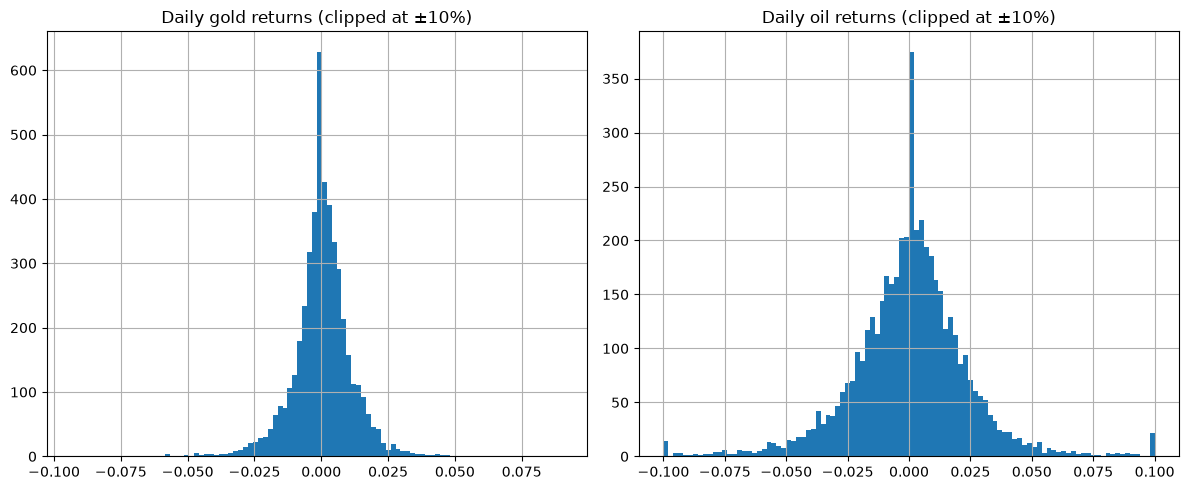

In [9]:
stats = pd.DataFrame({
    "mean (*10^4)": rets.mean() * 1e4,
    "volatility (%)": rets.std() * np.sqrt(260) * 100,
}).round(2)

display(stats.loc[["gold", "oil", "silver", "sp500", "vix"]])


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, a in zip(axes, ["gold", "oil"]):
    rets[a].clip(-0.1, 0.1).hist(bins=100, ax=ax)
    ax.set_title(f"Daily {a} returns (clipped at ±10%)")

plt.tight_layout()
plt.show()

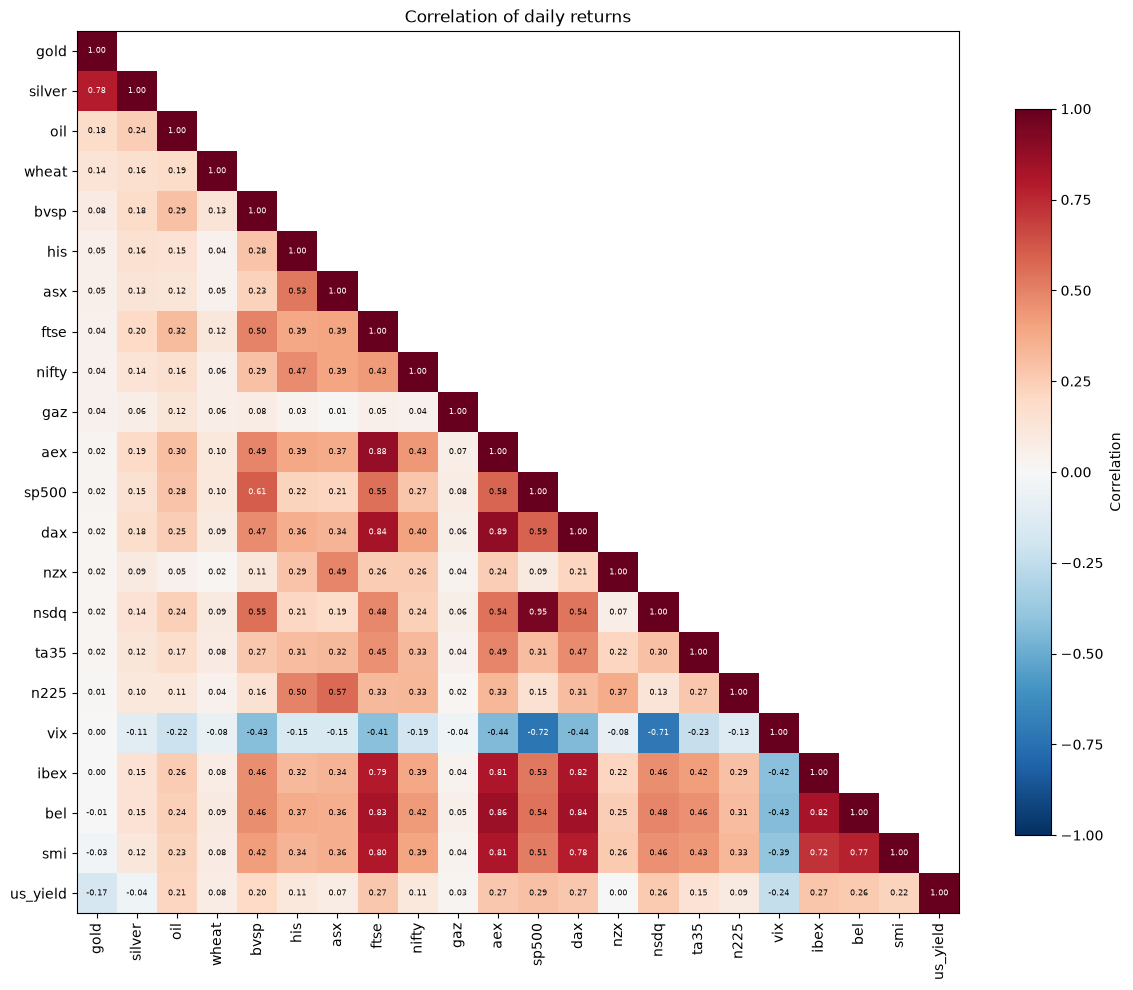

In [10]:
# This part was written by Claude
corr = rets.corr()

order = corr["gold"].sort_values(ascending=False).index
corr = corr.loc[order, order]

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
data = np.ma.masked_where(mask, corr.values)

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(data, cmap="RdBu_r", vmin=-1, vmax=1)

ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)

for i in range(len(corr)):
    for j in range(i + 1):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6,
                color="white" if abs(v) > 0.6 else "black")

fig.colorbar(im, ax=ax, shrink=0.8, label="Correlation")
ax.set_title("Correlation of daily returns")

plt.tight_layout()
plt.show()

- Volatility: gold 18%, S&P 500 20%, oil 43% a year.
- Gold moves with silver (0.78) and against the US yield (-0.17).
- Oil is closer to equities (about 0.3), so gold results may not carry over to oil.

## 2.4 Positions of traders: the CFTC Commitments of Traders report

We add the weekly positions of large traders, used to test H2.

- Weekly positions of large traders, disaggregated report, downloaded from the CFTC API from 2011.
- Groups: Managed Money (hedge funds, our main variable), Swap Dealers (including index investors), Producers, Other reportables, Non-reportables.
- Positions are observed on Tuesday and published on Friday after the settlement: we use them from the following Tuesday.
- Reports delayed by the late-2025 government shutdown are used from 30 December 2025, when the CFTC cleared its backlog ([announcements](https://www.cftc.gov/MarketReports/CommitmentsofTraders/HistoricalSpecialAnnouncements/index.htm)).

In [12]:
COT_URL = "https://publicreporting.cftc.gov/resource/72hh-3qpy.json"
COT_CODES = {"088691": "gold", "067651": "oil"}
COT_GROUPS = {
    "mm": ("m_money_positions_long_all", "m_money_positions_short_all"),
    "swap": ("swap_positions_long_all", "swap__positions_short_all"),
    "prod": ("prod_merc_positions_long", "prod_merc_positions_short"),
    "other": ("other_rept_positions_long", "other_rept_positions_short"),
    "nonrept": ("nonrept_positions_long_all", "nonrept_positions_short_all"),
}

def load_cot(start_date: str = "2011-01-01", end_date: str="2026-10-06") -> pd.DataFrame: # This function to fetch COT was written by Claude

    columns = [
        "cftc_contract_market_code",
        "report_date_as_yyyy_mm_dd",
        "open_interest_all",
        *[col for pair in COT_GROUPS.values() for col in pair],
    ]

    params = {
        "$select": ",".join(columns),
        "$where": (
            "cftc_contract_market_code IN ('088691', '067651') "
            f"AND report_date_as_yyyy_mm_dd >= '{start_date}' AND report_date_as_yyyy_mm_dd <= '{end_date}'"
        ),
        "$order": "report_date_as_yyyy_mm_dd ASC",
        "$limit": 50000,
    }

    rows = []
    offset = 0

    with requests.Session() as session:
        while True:
            params["$offset"] = offset
            response = session.get(COT_URL, params=params, timeout=60)
            response.raise_for_status()

            batch = response.json()
            if not batch:
                break

            rows.extend(batch)
            offset += len(batch)

            if len(batch) < params["$limit"]:
                break

    cot = pd.DataFrame(rows)

    cot["asset"] = (
        cot["cftc_contract_market_code"]
        .astype(str)
        .str.zfill(6)
        .map(COT_CODES)
    )

    cot = cot.rename(columns={
        "report_date_as_yyyy_mm_dd": "report_date",
        "open_interest_all": "oi",
        **{
            api_col: f"{group}_{position}"
            for group, pair in COT_GROUPS.items()
            for position, api_col in zip(("long", "short"), pair)
        },
    })

    cot["report_date"] = pd.to_datetime(cot["report_date"])

    numeric_cols = [
        "oi",
        *[f"{group}_{position}" for group in COT_GROUPS for position in ("long", "short")],
    ]
    cot[numeric_cols] = cot[numeric_cols].apply(pd.to_numeric, errors="coerce")

    return cot.drop(columns="cftc_contract_market_code").sort_values(
        ["asset", "report_date"]
    ).reset_index(drop=True)


def build_cot_features(cot: pd.DataFrame, asset: str, calendar: pd.DatetimeIndex) -> pd.DataFrame:

    df = cot[cot["asset"] == asset].set_index("report_date").sort_index()

    net = pd.DataFrame({
        f"cot_{group}_net": (df[f"{group}_long"] - df[f"{group}_short"]) / df["oi"]
        for group in COT_GROUPS
    })

    features = net.assign(
        cot_mm_net_chg_1w=net["cot_mm_net"].diff(1),
        cot_mm_net_chg_4w=net["cot_mm_net"].diff(4),
        cot_swap_net_chg_1w=net["cot_swap_net"].diff(1),
        cot_mm_net_z52=(net["cot_mm_net"] - net["cot_mm_net"].rolling(52).mean()) / net["cot_mm_net"].rolling(52).std(),
        cot_oi_chg_1w=df["oi"].pct_change(fill_method=None),
    )

    # Dating the data when it can be used, not when positions were observed
    usable = pd.Series(features.index + pd.Timedelta(days=7), index=features.index)
    usable[(features.index >= "2025-09-30") & (features.index <= "2025-12-16")] = pd.Timestamp("2025-12-30")
    features = features.groupby(usable.values).last()

    return features.reindex(calendar.union(features.index)).ffill().reindex(calendar)

       count        min        max
asset                             
gold     823 2011-01-04 2026-10-06
oil      823 2011-01-04 2026-10-06


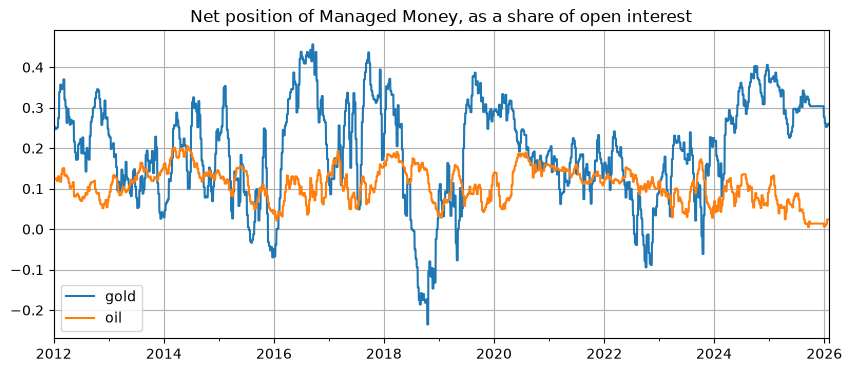

In [13]:
cot = load_cot()
print(cot.groupby("asset")["report_date"].agg(["count", "min", "max"]))

cot_plot = {
    a: build_cot_features(cot, a, cleaned_data.index)["cot_mm_net"].loc["2012":]
    for a in ["gold", "oil"]
}
pd.DataFrame(cot_plot).plot(figsize=(10, 4), grid=True, title="Net position of Managed Money, as a share of open interest")
plt.show()

Managed Money is net long on average (15% of open interest in gold, 8% in oil) and varies much more in gold.

# 3. Analytics and learning strategies

We define the features and the models, then explain how we tune them and how we measure their performance.

## 3.1 Features and target

The inputs of the models and the return we predict.

- 230 features, as in the paper: lags 1 to 10 of all 22 series, moving averages 2 to 10 of the target, VIX dummy.
- Target: next-day return of gold or oil.

In [14]:
def build_features(prices: pd.DataFrame, lag_order: int = 10, target_col: str = "oil", timing: str = "async"):

    ret = compute_returns(prices)
    return_cols = ret.columns.tolist()

    # compute lags up to order 10 of all the columns
    lag_features = {
        f"{col}_lag_{i}": ret[col].shift(i - 1 + info_lag(col, target_col, timing))
        for col in return_cols
        for i in range(1, lag_order + 1)
    }

    # moving averages on the target_col up to order 10. we exclude order 1 since it is equivalent to just seeing lag 1. It would introduce a duplicate column
    target_lag = info_lag(target_col, target_col, timing)
    ma_features = {
        f"{target_col}_ma{i}": ret[target_col].shift(target_lag).rolling(window=i, min_periods=i).mean()
        for i in range(2, lag_order + 1)
    }

    # the VIX dummy follows the same availability rule as the VIX itself
    vix_dummy = (prices["vix"].shift(info_lag("vix", target_col, timing)) > 20).astype("int8").rename("vix_dummy")

    features = pd.concat([pd.DataFrame(lag_features), pd.DataFrame(ma_features), vix_dummy.reindex(ret.index)], axis=1).dropna()
    target = ret[target_col].shift(-1).reindex(features.index).rename("target")
    ret_target = ret[target_col]

    # Verifications
    assert len(features.index) == features.index.nunique()
    assert features.isna().any().sum() == 0
    assert np.isfinite(features).all().all()
    assert target.iloc[:-1].notna().all()

    return features, target, ret_target

In [15]:
features_oil, target_oil, ret_oil = build_features(cleaned_data, lag_order=10, target_col="oil")
features_gold, target_gold, ret_gold = build_features(cleaned_data, lag_order=10, target_col="gold")

print("Number of features:", features_gold.shape[1], "(22 series x 10 lags, 9 moving averages, 1 VIX dummy)")

Number of features: 230 (22 series x 10 lags, 9 moving averages, 1 VIX dummy)


## 3.2 Algorithms

The four models and how a forecast becomes a position.

- Decision Tree, Random Forest, Gradient Boosting, XGBoost.
- Forecasts become positions with `TimingMeanVariance` (clip at ±0.25).
- `skfin` is imported unchanged; we only add a `transform` method to the tree models so they fit in its pipelines.

In [16]:
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor


class DecisionTreeRegressor(DecisionTreeRegressor):
    def transform(self, X):
        return self.predict(X)


class RandomForestRegressor(RandomForestRegressor):
    def transform(self, X):
        return self.predict(X)


class GradientBoostingRegressor(GradientBoostingRegressor):
    def transform(self, X):
        return self.predict(X)


class XGBRegressor(XGBRegressor):
    def transform(self, X):
        return self.predict(X)

## 3.3 Data partitioning: training, validation and test

How the sample is split between tuning and testing.

- **Tuning:** walk-forward backtests on 2012–2020.
- **Test:** walk-forward on 2021-01-01 to 2026-01-30, never used for tuning.
- Models are re-trained every 40 days on a rolling window.

In [17]:
def prepare_tuning_data(features: pd.DataFrame, target: pd.Series, tuning_end_date: str = "2020-12-31"):

    X_tune = features.loc[:tuning_end_date]
    y_tune = target.reindex(X_tune.index)

    # The label of the last day is the first return of the test period
    return X_tune.iloc[:-1], y_tune.iloc[:-1]

## 3.4 Parameter selection and optimisation

How we choose the hyper-parameters of each model, using only data before 2021.

- 20 random draws per model (`ParameterSampler`), including the training window (120 to 1000 days).
- Each draw is scored by the Sharpe ratio of its 2012–2020 backtest; the best one is kept.
- The best of many draws is partly luck, so we compare it with the standard error of the Sharpe ratio (Lo, 2002).
- The selected model of each asset is the one with the best tuning Sharpe.

In [18]:
TRAIN_WINDOWS = [120, 250, 500, 1000]
N_ITER = 20
TUNING_START_DATE = "2012-01-01"
TUNING_END_DATE = "2020-12-31"
PREDICTION_START_DATE = "2021-01-01"
NUM_PERIOD_PER_YEAR = 260 # The common calendar has about 260 rows per year, the frequency detected by sharpe_ratio

models_and_params = {
    "Decision Tree": (
        DecisionTreeRegressor(random_state=RNDM_SEED),
        {
            "max_depth": randint(1, 6),
            "min_samples_leaf": randint(5, 50),
            "max_features": uniform(0.1, 0.9),
        },
    ),
    "Random Forest": (
        RandomForestRegressor(n_estimators=200, random_state=RNDM_SEED, n_jobs=1),
        {
            "max_depth": randint(2, 9),
            "min_samples_leaf": randint(5, 50),
            "max_features": uniform(0.1, 0.9),
        },
    ),
    "Gradient Boosting": (
        GradientBoostingRegressor(random_state=RNDM_SEED),
        {
            "n_estimators": randint(50, 300),
            "learning_rate": loguniform(1e-2, 1e-1),
            "max_depth": randint(1, 4),
            "min_samples_leaf": randint(5, 50),
            "subsample": uniform(0.5, 0.5),
        },
    ),
    "XGBoost": (
        XGBRegressor(random_state=RNDM_SEED, n_jobs=1),
        {
            "n_estimators": randint(50, 300),
            "learning_rate": loguniform(1e-2, 1e-1),
            "max_depth": randint(1, 4),
            "subsample": uniform(0.5, 0.5),
            "colsample_bytree": uniform(0.2, 0.8),
            "reg_lambda": loguniform(1, 100),
            "reg_alpha": loguniform(1e-8, 1e-2),
        },
    ),
}

X_tune_oil, y_tune_oil = prepare_tuning_data(features=features_oil, target=target_oil, tuning_end_date=TUNING_END_DATE)
X_tune_gold, y_tune_gold = prepare_tuning_data(features=features_gold, target=target_gold, tuning_end_date=TUNING_END_DATE)

In [19]:
def sharpe_ratio_std(pnl: pd.Series, num_period_per_year: int = NUM_PERIOD_PER_YEAR) -> float:
    """Standard error of an annualised Sharpe ratio (Lo, 2002)."""
    sr = sharpe_ratio(pnl, num_period_per_year=num_period_per_year) / np.sqrt(num_period_per_year)
    return np.sqrt(num_period_per_year) * np.sqrt((1 + 0.5 * sr**2) / len(pnl))

def tuning_backtest(model, prm, features, target, ret):
    prm = dict(prm)
    window = prm.pop("train_window")
    estimator = make_pipeline(clone(model).set_params(**prm), TimingMeanVariance(a_min=-0.25, a_max=0.25))
    pnl_ = Backtester(estimator, max_train_size=window, test_size=40, start_date=TUNING_START_DATE,
                      end_date=TUNING_END_DATE).train(features, target, ret).dropna()
    return pnl_

def hyperparameter_optimization(features: pd.DataFrame, target: pd.Series, ret: pd.Series,
                                models_and_params: dict, n_iter: int = N_ITER):

    best_models, best_windows, summary = {}, {}, {}

    for name, (model, param_distributions) in models_and_params.items():
        draws = list(ParameterSampler(param_distributions={**param_distributions, "train_window": TRAIN_WINDOWS},
                                      n_iter=n_iter, random_state=RNDM_SEED))
        pnls = Parallel(n_jobs=-1)(delayed(tuning_backtest)(model, prm, features, target, ret) for prm in draws)

        results = pd.DataFrame(draws).assign(sr=[pnl_.pipe(sharpe_ratio) for pnl_ in pnls]).sort_values("sr")
        best = results.iloc[-1].drop("sr").to_dict()
        window = int(best.pop("train_window"))
        best = {k: int(v) if k in ("max_depth", "min_samples_leaf", "n_estimators") else v for k, v in best.items()}

        best_models[name] = clone(model).set_params(**best)
        best_windows[name] = window
        summary[name] = {
            "best Sharpe": results["sr"].iloc[-1],
            "std. error (Lo)": sharpe_ratio_std(pnls[results.index[-1]]),
            "range of Sharpe": results["sr"].max() - results["sr"].min(),
            "train window": window,
            **best,
        }

    table = pd.DataFrame(summary).T
    display(table.astype(object).where(table.notna(), "").round(3))

    return best_models, best_windows, table["best Sharpe"].astype(float).idxmax()

In [20]:
print("OIL")
best_models_oil, best_windows_oil, best_name_oil = hyperparameter_optimization(X_tune_oil, y_tune_oil, ret_oil, models_and_params)
print("GOLD")
best_models_gold, best_windows_gold, best_name_gold = hyperparameter_optimization(X_tune_gold, y_tune_gold, ret_gold, models_and_params)
print("Model selected before the test period. Gold:", best_name_gold, "| Oil:", best_name_oil)

OIL


,best Sharpe,std. error (Lo),range of Sharpe,train window,max_depth,max_features,min_samples_leaf,learning_rate,n_estimators,subsample,colsample_bytree,reg_alpha,reg_lambda
Decision Tree,0.437101,0.332826,1.095678,1000.0,1.0,0.332902,44.0,,,,,,
Random Forest,0.047747,0.332766,0.780975,1000.0,4.0,0.650668,46.0,,,,,,
Gradient Boosting,0.015376,0.332765,1.185442,1000.0,2.0,,13.0,0.088897,139.0,0.548836,,,
XGBoost,0.016621,0.332765,0.902228,1000.0,1.0,,,0.036957,240.0,0.697575,0.366353,0.001132,7.934294


GOLD


,best Sharpe,std. error (Lo),range of Sharpe,train window,max_depth,max_features,min_samples_leaf,learning_rate,n_estimators,subsample,colsample_bytree,reg_alpha,reg_lambda
Decision Tree,0.472267,0.332836,0.989024,1000.0,3.0,0.513324,40.0,,,,,,
Random Forest,0.313198,0.332796,0.947004,250.0,6.0,0.849875,39.0,,,,,,
Gradient Boosting,0.459532,0.332833,1.321051,250.0,2.0,,44.0,0.024607,181.0,0.655856,,,
XGBoost,0.264268,0.332787,0.838675,500.0,1.0,,,0.010367,137.0,0.50704,0.332214,0.000002,3.863459


Model selected before the test period. Gold: Decision Tree | Oil: Decision Tree


- Best tuning Sharpe ratios: 0.26 to 0.47 (gold), 0.02 to 0.44 (oil), with a standard error of 0.33. None is clearly above zero.
- The Decision Tree is selected for both assets, almost tied with other models. We report all four models.

## 3.5 Implementation of the backtest and performance metrics

The backtest function and the measures we report.

- $R^2$ against a zero forecast and against the historical mean (the harder benchmark).
- Cumulated PnL, Sharpe ratio and drawdown from `skfin`, without transaction costs, plus the standard error of the Sharpe ratio: two Sharpe ratios less than about two standard errors apart cannot be told apart.
- Benchmark: buy & hold. PnL is rescaled to 10% annual volatility for display.

In [21]:
def run_backtest(features, target, ret, model, train_window, start_date=PREDICTION_START_DATE, test_size=40, name=None):

    estimator = make_pipeline(clone(model), TimingMeanVariance(a_min=-0.25, a_max=0.25))
    bt = Backtester(
        estimator=estimator,
        max_train_size=train_window,
        test_size=test_size,
        pred_lag=1,
        start_date=start_date,
        name=name,
    )
    bt.compute_holdings(features, target, n_jobs=-1).compute_pnl(ret)

    # The fitted pipelines also give the forecast before it is converted into a position
    tests = [test for _, test in bt.cv_.split(features)]
    forecasts = [m[:-1].predict(features.values[test]) for test, m in zip(tests, bt.estimators_)]
    idx = features.index[np.concatenate(tests)]
    bt.predictions_ = pd.Series(np.concatenate(forecasts), index=idx).loc[start_date:]
    bt.pnl_ = bt.pnl_.dropna()

    return bt

def forecast_metrics(bt, target, ret) -> dict:

    pred = bt.predictions_
    actual = target.reindex(pred.index).dropna()
    pred = pred.loc[actual.index]
    hist_mean = ret.expanding().mean().reindex(actual.index)

    return {
        "R2 vs zero": 1 - ((actual - pred) ** 2).sum() / (actual ** 2).sum(),
        "R2 vs hist. mean": 1 - ((actual - pred) ** 2).sum() / ((actual - hist_mean) ** 2).sum(),
    }

def rescale(pnl: pd.Series, vol: float = 0.10) -> pd.Series:
    return pnl * vol / (pnl.std() * np.sqrt(NUM_PERIOD_PER_YEAR))

def trading_metrics(pnl: pd.Series) -> dict:

    return {
        "Cumulated PnL (10% vol)": rescale(pnl).sum(),
        "Sharpe": sharpe_ratio(pnl),
        "Sharpe std. error (Lo)": sharpe_ratio_std(pnl),
        "Max drawdown": drawdown(pnl, window=36, num_period_per_year=NUM_PERIOD_PER_YEAR).min(),
    }

def display_results(features, target, ret, best_models, best_windows, start_date=PREDICTION_START_DATE, asset="Oil"):

    backtests = {
        name: run_backtest(features, target, ret, model, best_windows[name], start_date=start_date, name=name)
        for name, model in best_models.items()
    }
    pnl = pd.DataFrame({name: bt.pnl_ for name, bt in backtests.items()})
    series = {**pnl.to_dict("series"), "Buy & hold": ret.reindex(pnl.index)}

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    line({c: rescale(s) for c, s in series.items()},
         cumsum=True, title=f"Cumulated PnL for {asset} (10% annual volatility)", ax=axes[0], loc="best")
    line({c: drawdown(s, window=36, num_period_per_year=NUM_PERIOD_PER_YEAR) for c, s in series.items()},
         title=f"Drawdown for {asset} (risk units)", ax=axes[1], loc="best", legend_sharpe_ratio=False)
    plt.tight_layout()
    plt.show()

    print("Forecast performance")
    display(pd.DataFrame({n: forecast_metrics(bt, target, ret) for n, bt in backtests.items()}).T.round(4))

    print("Trading performance, without transaction costs")
    display(pd.DataFrame({n: trading_metrics(s) for n, s in series.items()}).T.round(2))

    print("Sharpe ratio per year")
    display(pd.DataFrame({
        n: s.groupby(s.index.year).apply(lambda x: x.mean() / x.std() * np.sqrt(NUM_PERIOD_PER_YEAR))
        for n, s in series.items()
    }).T.round(2))

    return backtests

**Feature selection:** tree importances averaged over the re-trained models on 2012–2020; we keep features above the average importance.

In [22]:
def get_feature_importance(estimators) -> np.ndarray:
    """Importance given by the tree model of each pipeline re-trained by Backtester."""
    return np.stack([m.steps[0][1].feature_importances_ for m in estimators])

def features_selector_importance(model, train_window, features, target, ret, show_features: bool = False):

    estimator = make_pipeline(clone(model), TimingMeanVariance(a_min=-0.25, a_max=0.25))
    m = Backtester(estimator, max_train_size=train_window, test_size=40, start_date=TUNING_START_DATE,
                   end_date=TUNING_END_DATE)
    m.train(features, target, ret)

    importance = pd.Series(get_feature_importance(m.estimators_).mean(axis=0), index=features.columns).sort_values(ascending=False)
    if show_features:
        display(importance.head(20).to_frame("Importance"))

    # Keep the features above the average importance, 1/230 when importances sum to one
    return importance[importance > importance.mean()].index.to_list()

# 4. Empirical results: baseline and robustness

We test H1, evaluate the models on 2021–2026, test H2, then check whether the results hold under other choices.

## 4.1 H1: replicating the paper

We try to reproduce the paper's result with its own protocol.

**H1:** *the predictors selected in the paper, rebuilt from open data and fed to the most performant model, deliver an out-of-sample performance comparable to the one reported in the paper.*

- Paper's protocol: Feb 2011 to Feb 2023, split on 26 September 2019, target $r(t)$, its selected predictors and reported hyper-parameters.
- Metric: $RSE = MSE / Var(r) = 1 - R^2$.
- **Suspicion:** if the 3-day moving average includes day *t*, then $r(t) = 3 \times MA_3(t) - r(t-1) - r(t-2)$, exactly the paper's top 3 variables.
- We therefore run each model twice: moving averages of past returns only (correct), and moving averages including $r(t)$.

In [23]:
PAPER_LAGS = {
    "target": [1, 2, 3, 4, 5, 6, 7, 8, 9],
    "sp500": [1, 2, 7],
    "ta35": [1, 2],
    "ibex": [1, 9],
    "aex": [1, 4, 5, 6, 7, 8, 10],
    "bel": [1, 4, 5, 6, 7, 8, 9],
    "asx": [1, 8],
    "vix": [1],
    "us_yield": [1, 3],
    "japan_yield": [1],
    "nsdq": [2, 10],
    "nifty": [2, 4, 6, 7, 8],
    "n225": [2, 3, 4, 5, 6, 7, 8, 9],
    "bvsp": [3],
    "smi": [4, 5],
    "his": [4, 5],
    "gaz": [6, 9],
    "ftse": [6, 7, 9],
    "silver": [8, 9, 10],
    "wheat": [9],
    "dax": [10],
    "nzx": [10],
}
PAPER_MA = [3, 5, 10]
PAPER_VIX_DUMMY_LAGS = [1, 3, 10]
PAPER_RSE = {"Decision Tree": 0.6401, "Random Forest": 0.43635, "Gradient Boosting": 0.16593, "XGBoost": 0.1928}
PAPER_START, PAPER_END, PAPER_SPLIT = "2011-02-01", "2023-02-28", "2019-09-26"

paper_models = {
    "Decision Tree": DecisionTreeRegressor(max_leaf_nodes=17, random_state=RNDM_SEED),
    "Random Forest": RandomForestRegressor(n_estimators=463, max_features=1 / 3, random_state=RNDM_SEED, n_jobs=1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=1100, max_depth=15, learning_rate=0.01, subsample=0.5,
                                                   min_samples_leaf=10, random_state=RNDM_SEED),
    "XGBoost": XGBRegressor(n_estimators=1000, max_depth=6, learning_rate=0.01, subsample=0.8, colsample_bytree=0.8,
                            random_state=RNDM_SEED, n_jobs=1),
}

def build_paper_design(prices: pd.DataFrame, target_col: str, ma_contains_target: bool) -> pd.DataFrame:

    ret = compute_returns(prices)
    columns = {}

    for col, lags in PAPER_LAGS.items():
        source = target_col if col == "target" else col
        for i in lags:
            columns[f"{source}_l{i}"] = ret[source].shift(i)

    base = ret[target_col] if ma_contains_target else ret[target_col].shift(1)
    for i in PAPER_MA:
        columns[f"{target_col}_ma{i}"] = base.rolling(i).mean()

    columns["vix"] = prices["vix"].reindex(ret.index)
    design = pd.DataFrame(columns)
    for i in PAPER_VIX_DUMMY_LAGS:
        design[f"vix_dummy_l{i}"] = (design["vix"].shift(i) > 20).astype("int8")
    design = design.drop(columns="vix")

    design["y"] = ret[target_col]
    return design.dropna().loc[PAPER_START:PAPER_END]

def replicate_one(name, model, prices, target_col, ma_contains_target):

    design = build_paper_design(prices, target_col, ma_contains_target)
    train, test = design.loc[:PAPER_SPLIT], design.loc[PAPER_SPLIT:].iloc[1:]

    fitted = clone(model).fit(train.drop(columns="y"), train["y"])
    pred = pd.Series(fitted.predict(test.drop(columns="y")), index=test.index)
    mse = ((test["y"] - pred) ** 2).mean()

    return {
        "asset": target_col,
        "model": name,
        "ma_contains_target": ma_contains_target,
        "MSE": mse,
        "RSE": mse / test["y"].var(),
    }

replication = pd.DataFrame(Parallel(n_jobs=-1)(
    delayed(replicate_one)(name, model, paper_data, asset, leak)
    for asset in ["gold", "oil"]
    for name, model in paper_models.items()
    for leak in [False, True]
))

design_check = build_paper_design(paper_data, "gold", ma_contains_target=True)
identity_error = (3 * design_check["gold_ma3"] - design_check["gold_l1"] - design_check["gold_l2"] - design_check["y"]).abs().max()
print("Largest error of the identity r(t) = 3 x MA3(t) - r(t-1) - r(t-2):", f"{identity_error:.1e}")
print("Number of predictors:", design_check.shape[1] - 1)

Largest error of the identity r(t) = 3 x MA3(t) - r(t-1) - r(t-2): 0.0e+00
Number of predictors: 73


In [24]:
pivot = replication.pivot(index=["asset", "model"], columns="ma_contains_target", values=["RSE", "MSE"])

h1_table = pd.DataFrame({
    "RSE paper": [PAPER_RSE[m] if a == "gold" else np.nan for a, m in pivot.index],
    "RSE, past returns only": pivot[("RSE", False)],
    "RSE, MA contains r(t)": pivot[("RSE", True)],
    "MSE, past returns only": pivot[("MSE", False)],
    "MSE, MA contains r(t)": pivot[("MSE", True)],
}, index=pivot.index)

display(h1_table.loc[["gold", "oil"]].round({"RSE paper": 3,"RSE, past returns only": 3,"RSE, MA contains r(t)": 3,"MSE, past returns only": 6,"MSE, MA contains r(t)": 6,}))
print("MSE reported in the paper for GBRT and XGBoost: 1.86e-05")

RSE paper  RSE, past returns only  \
asset model                                                  
gold  Decision Tree          0.640                   1.555   
      Gradient Boosting      0.166                   1.052   
      Random Forest          0.436                   1.051   
      XGBoost                0.193                   1.024   
oil   Decision Tree            NaN                   1.409   
      Gradient Boosting        NaN                   1.110   
      Random Forest            NaN                   1.076   
      XGBoost                  NaN                   1.073   

                         RSE, MA contains r(t)  MSE, past returns only  \
asset model                                                              
gold  Decision Tree                      0.598                0.000173   
      Gradient Boosting                  0.107                0.000117   
      Random Forest                      0.363                0.000117   
      XGBoost                            0.169                0.000114   
oil   Decision Tree                      0.677                0.002037   
      Gradient Boosting                  0.399                0.001605   
      Random Forest                      0.621                0.001556   
      XGBoost                            0.487                0.001552   

                         MSE, MA contains r(t)  
asset model                                     
gold  Decision Tree                   0.000067  
      Gradient Boosting               0.000012  
      Random Forest                   0.000041  
      XGBoost                         0.000019  
oil   Decision Tree                   0.000979  
      Gradient Boosting               0.000577  
      Random Forest                   0.000899  
      XGBoost                         0.000704

MSE reported in the paper for GBRT and XGBoost: 1.86e-05


**H1 rejected.**
- Correct design: RSE of 1.02 to 1.56 on gold, worse than the mean (paper: 0.17 to 0.64).
- Moving averages including $r(t)$: 0.11 (GB), 0.17 (XGBoost), 0.36 (RF), 0.60 (tree), close to the paper and in the same order.
- Consistent with a look-ahead bias in the paper, but not a proof: its code is not public.
- Oil: same pattern (1.07 to 1.41, against 0.40 to 0.68).

## 4.2 Baseline results: a real walk-forward forecast

We test the models as a trader would use them, on data never used for tuning, and compare them with buy & hold.

All 230 features, tuned on 2012–2020, tested on 2021–2026, target $r(t+1)$.

### 4.2.1 Gold

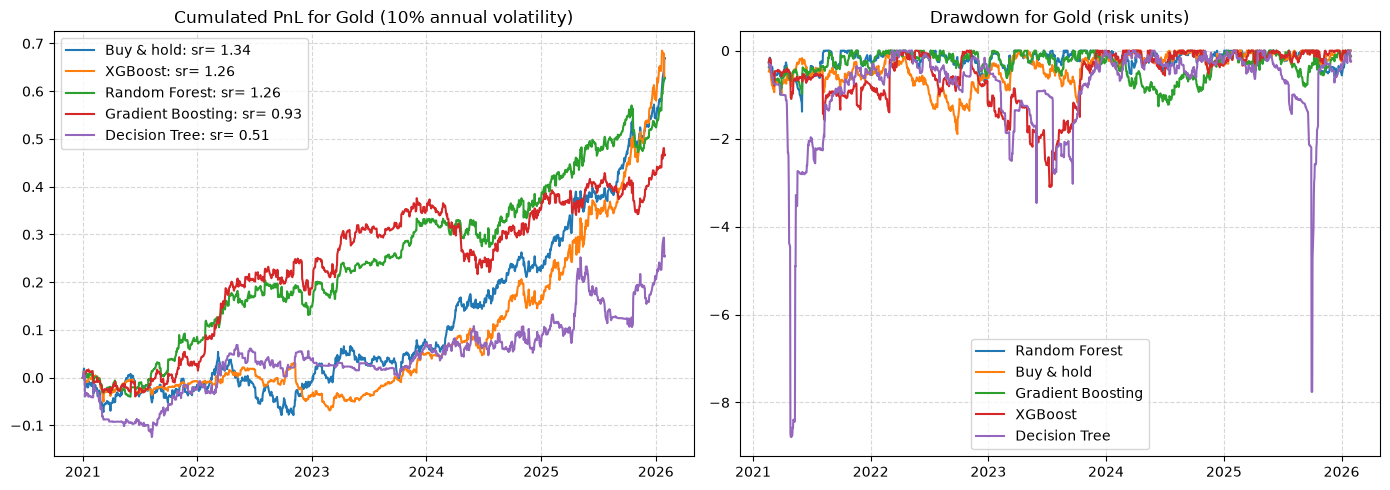

Forecast performance


,R2 vs zero,R2 vs hist. mean
Decision Tree,-0.0455,-0.0505
Random Forest,0.0026,-0.0021
Gradient Boosting,-0.0299,-0.0348
XGBoost,0.0068,0.0021


Trading performance, without transaction costs


,Cumulated PnL (10% vol),Sharpe,Sharpe std. error (Lo),Max drawdown
Decision Tree,0.25,0.51,0.44,-8.79
Random Forest,0.63,1.26,0.44,-1.39
Gradient Boosting,0.47,0.93,0.44,-1.27
XGBoost,0.63,1.26,0.44,-3.10
Buy & hold,0.67,1.34,0.44,-1.90


Sharpe ratio per year


,2021,2022,2023,2024,2025,2026
Decision Tree,-0.28,0.73,0.82,0.02,0.96,2.86
Random Forest,1.25,0.66,2.51,0.43,1.19,7.84
Gradient Boosting,0.39,1.52,1.86,0.06,0.65,3.43
XGBoost,-0.13,-0.50,1.74,1.20,2.55,2.02
Buy & hold,-0.16,0.07,1.01,1.66,2.48,10.65


In [25]:
bt_gold = display_results(features=features_gold, target=target_gold, ret=ret_gold, best_models=best_models_gold,
                          best_windows=best_windows_gold, asset="Gold")

- $R^2$ from -4.6% to +0.7%; only XGBoost beats the historical mean.
- **No model beats buy & hold (1.34):** Random Forest and XGBoost 1.26, Gradient Boosting 0.93, Decision Tree 0.51.
- The Random Forest earns as much as buy & hold but not in the same years: positive in 2021–2023 when gold was flat, with a smaller drawdown.
- The Decision Tree drawdown is inflated: `drawdown` divides by a 36-day volatility, near zero when the tree takes tiny positions.

### 4.2.2 Extension: oil

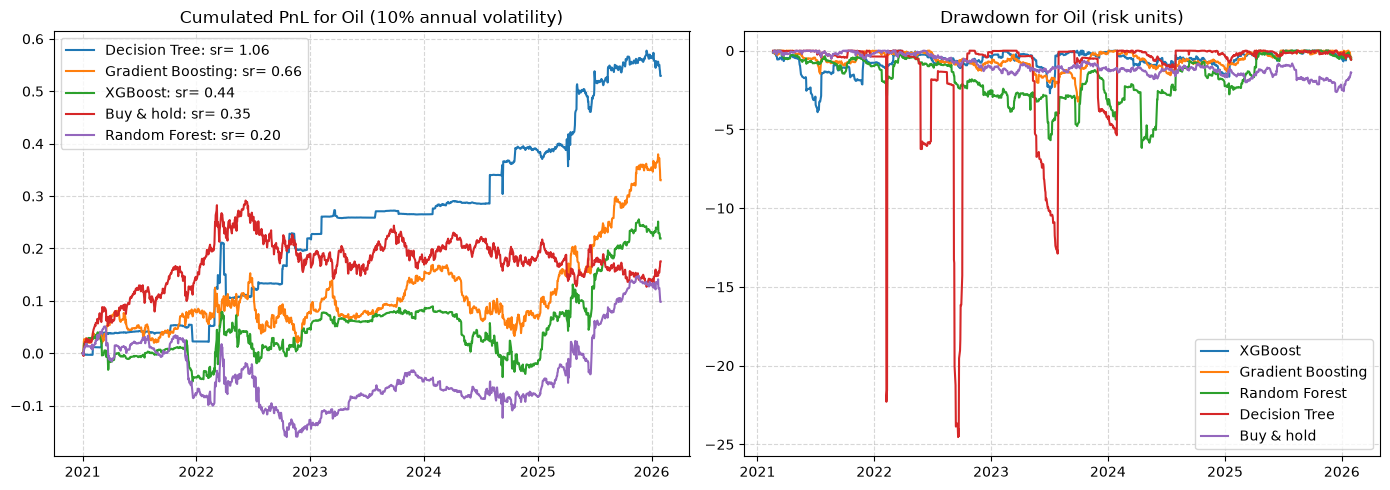

Forecast performance


,R2 vs zero,R2 vs hist. mean
Decision Tree,-0.0044,-0.0046
Random Forest,-0.0145,-0.0147
Gradient Boosting,-0.1514,-0.1516
XGBoost,-0.0296,-0.0298


Trading performance, without transaction costs


,Cumulated PnL (10% vol),Sharpe,Sharpe std. error (Lo),Max drawdown
Decision Tree,0.53,1.06,0.44,-24.54
Random Forest,0.10,0.20,0.44,-6.18
Gradient Boosting,0.33,0.66,0.44,-3.24
XGBoost,0.22,0.44,0.44,-3.91
Buy & hold,0.18,0.35,0.44,-2.63


Sharpe ratio per year


,2021,2022,2023,2024,2025,2026
Decision Tree,0.50,1.39,1.14,1.25,1.36,-4.85
Random Forest,-0.94,-0.35,1.53,-0.33,1.76,-3.90
Gradient Boosting,1.08,0.01,0.98,-0.67,2.52,-2.27
XGBoost,-0.70,0.70,0.85,-0.90,2.13,-1.36
Buy & hold,1.43,0.38,-0.17,0.15,-0.55,4.85


In [26]:
bt_oil = display_results(features=features_oil, target=target_oil, ret=ret_oil, best_models=best_models_oil,
                         best_windows=best_windows_oil, asset="Oil")

- All $R^2$ negative (-15.1% to -0.4%).
- Three models beat buy & hold (0.35), including the Decision Tree at 1.06. But with other seeds it falls to -0.10 to 0.47 (section 4.4): luck, not signal.
- No reliable strategy on oil.

## 4.3 H2: adding the positions of traders

We add the CFTC variables to the models and check whether forecasts and Sharpe ratios improve.

**H2:** *adding the net positions of hedge funds and of the other groups of the CFTC Commitments of Traders report improves out-of-sample predictions.*

- 10 CFTC variables: net position of the 5 groups, changes in Managed Money and Swap Dealers positions, Managed Money z-score, change in open interest.
- Everything else identical. Tested with all 230 features and with a compact set of 20 features (lags and moving averages of the target, plus the VIX dummy).

In [27]:
def compact_columns(features: pd.DataFrame, target_col: str) -> list[str]:
    return [c for c in features.columns if c.startswith(f"{target_col}_") or c == "vix_dummy"]

def compare_with_cot(features, target, ret, best_models, best_windows, asset):

    cot_features = build_cot_features(cot, asset, features.index).dropna()
    common = cot_features.index
    specs = {"full": features.columns.to_list(), "compact": compact_columns(features, asset)}

    rows, curves = [], {}
    for spec, columns in specs.items():
        X_without = features.loc[common, columns]
        X_with = X_without.join(cot_features)
        y = target.reindex(common)

        for name, model in best_models.items():
            without = run_backtest(X_without, y, ret, model, best_windows[name])
            with_cot = run_backtest(X_with, y, ret, model, best_windows[name])

            rows.append({
                "asset": asset, "features": spec, "model": name,
                "R2 without": forecast_metrics(without, y, ret)["R2 vs zero"],
                "R2 with CoT": forecast_metrics(with_cot, y, ret)["R2 vs zero"],
                "Sharpe without": sharpe_ratio(without.pnl_),
                "Sharpe with CoT": sharpe_ratio(with_cot.pnl_),
            })
            curves[(spec, name)] = (without.pnl_, with_cot.pnl_)

    return pd.DataFrame(rows), curves

In [28]:
h2_gold, curves_gold = compare_with_cot(features_gold, target_gold, ret_gold, best_models_gold, best_windows_gold, "gold")
h2_oil, curves_oil = compare_with_cot(features_oil, target_oil, ret_oil, best_models_oil, best_windows_oil, "oil")

h2_table = pd.concat([h2_gold, h2_oil]).set_index(["asset", "features", "model"])
h2_table["R2 gain"] = h2_table["R2 with CoT"] - h2_table["R2 without"]
h2_table["Sharpe gain"] = h2_table["Sharpe with CoT"] - h2_table["Sharpe without"]

display(h2_table[["R2 without", "R2 with CoT", "R2 gain", "Sharpe without", "Sharpe with CoT", "Sharpe gain"]].round(4))

print("Models where the R2 improves:", int((h2_table["R2 gain"] > 0).sum()), "out of", len(h2_table))
print("Models where the Sharpe improves:", int((h2_table["Sharpe gain"] > 0).sum()), "out of", len(h2_table))

R2 without  R2 with CoT  R2 gain  \
asset features model                                                 
gold  full     Decision Tree         -0.0455      -0.0342   0.0113   
               Random Forest          0.0026       0.0034   0.0008   
               Gradient Boosting     -0.0299      -0.0321  -0.0022   
               XGBoost                0.0068       0.0074   0.0005   
      compact  Decision Tree         -0.0455      -0.0538  -0.0084   
               Random Forest         -0.0066      -0.0073  -0.0007   
               Gradient Boosting     -0.0444      -0.0537  -0.0093   
               XGBoost               -0.0052      -0.0052  -0.0000   
oil   full     Decision Tree         -0.0044      -0.0213  -0.0169   
               Random Forest         -0.0145      -0.0145   0.0001   
               Gradient Boosting     -0.1514      -0.1502   0.0011   
               XGBoost               -0.0296      -0.0271   0.0025   
      compact  Decision Tree         -0.0077      -0.0118  -0.0040   
               Random Forest         -0.0105      -0.0116  -0.0012   
               Gradient Boosting     -0.0687      -0.0934  -0.0246   
               XGBoost               -0.0143      -0.0216  -0.0073   

                                  Sharpe without  Sharpe with CoT  Sharpe gain  
asset features model                                                            
gold  full     Decision Tree              0.5099           0.7724       0.2625  
               Random Forest              1.2559           1.2860       0.0301  
               Gradient Boosting          0.9345           0.8671      -0.0673  
               XGBoost                    1.2582           1.2689       0.0107  
      compact  Decision Tree             -0.1126           0.1238       0.2364  
               Random Forest              1.0382           0.9953      -0.0429  
               Gradient Boosting          0.6957           0.7086       0.0129  
               XGBoost                    0.5024           0.4799      -0.0225  
oil   full     Decision Tree              1.0599           0.2678      -0.7920  
               Random Forest              0.1965           0.0884      -0.1081  
               Gradient Boosting          0.6613           0.2733      -0.3879  
               XGBoost                    0.4389           0.5959       0.1570  
      compact  Decision Tree              0.4437           0.3644      -0.0793  
               Random Forest              0.4251           0.3407      -0.0844  
               Gradient Boosting          0.6453           0.6951       0.0497  
               XGBoost                    0.4325           0.1442      -0.2883

Models where the R2 improves: 6 out of 16
Models where the Sharpe improves: 7 out of 16


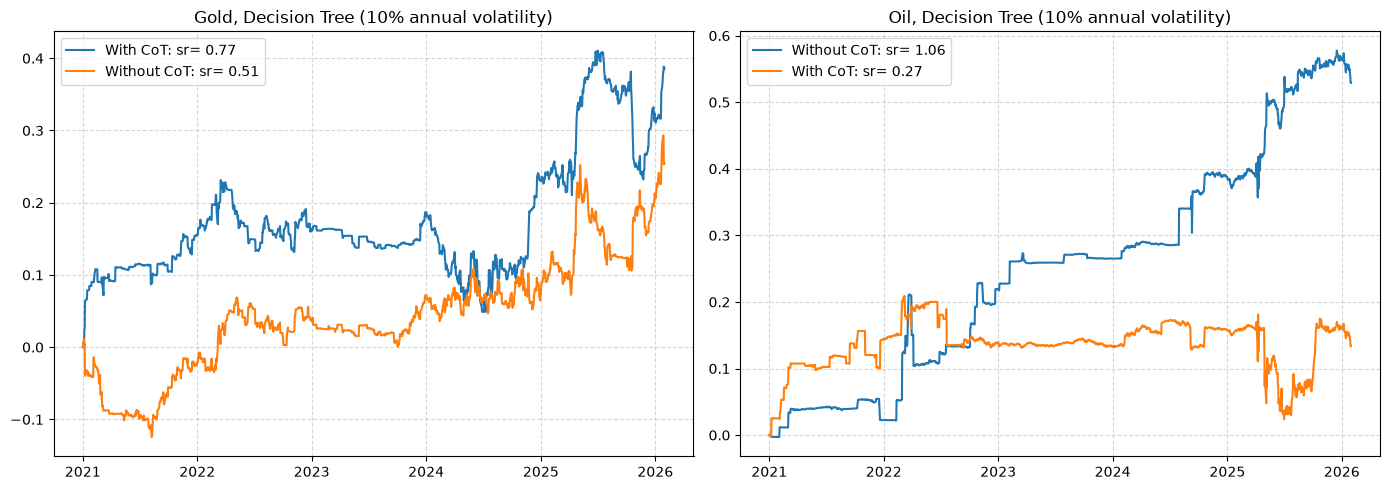

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, asset, curves, best in zip(axes, ["Gold", "Oil"], [curves_gold, curves_oil], [best_name_gold, best_name_oil]):
    without, with_cot = curves[("full", best)]
    line({"Without CoT": rescale(without), "With CoT": rescale(with_cot)}, cumsum=True, ax=ax, loc="best",
         title=f"{asset}, {best} (10% annual volatility)")

plt.tight_layout()
plt.show()

**H2 not supported.**
- $R^2$ improves in 6 cases out of 16, by less than 2.5 points; Sharpe in 7 out of 16.
- Best gold models barely move (e.g. Random Forest 1.26 to 1.29), far below the standard error of 0.44.
- Weekly data published with a delay may already be priced in.

## 4.4 Robustness tests

We change one choice at a time to see whether the conclusions still hold.

### 4.4.1 Sensitivity to the dating of the features

- `async` (baseline): closing times respected.
- `gap`: every series lagged one more day.
- `naive`: US data used the same day, i.e. before it is known.

In [30]:
def timing_sensitivity(target_col, model, window):
    rows = {}
    for timing in ["async", "gap", "naive"]:
        X, y, ret = build_features(cleaned_data, lag_order=10, target_col=target_col, timing=timing)
        bt = run_backtest(X, y, ret, model, window)
        rows[timing] = {**forecast_metrics(bt, y, ret), "Sharpe": sharpe_ratio(bt.pnl_)}
    return pd.DataFrame(rows).T.round(4)

print("Gold,", best_name_gold)
display(timing_sensitivity("gold", best_models_gold[best_name_gold], best_windows_gold[best_name_gold]))
print("Oil,", best_name_oil)
display(timing_sensitivity("oil", best_models_oil[best_name_oil], best_windows_oil[best_name_oil]))

Gold, Decision Tree


,R2 vs zero,R2 vs hist. mean,Sharpe
async,-0.0455,-0.0505,0.5099
gap,-0.0370,-0.0419,0.7812
naive,-0.0289,-0.0338,1.1181


Oil, Decision Tree


,R2 vs zero,R2 vs hist. mean,Sharpe
async,-0.0044,-0.0046,1.0599
gap,-0.0267,-0.0269,0.5826
naive,-0.0044,-0.0046,1.0599


- The tree moves a lot (gold 0.51 to 1.12, oil 0.58 to 1.06), within 1.4 standard errors; $R^2$ always negative.
- `naive` is best on gold, as expected from using information not yet available.

### 4.4.2 Feature selection

In [31]:
def selection_summary(features, target, ret, best_models, best_windows, selected: dict) -> pd.DataFrame:
    rows = {}
    for spec, columns in selected.items():
        for name, model in best_models.items():
            bt = run_backtest(features[columns], target, ret, model, best_windows[name])
            rows[(spec, name)] = {"n features": len(columns), **forecast_metrics(bt, target, ret), "Sharpe": sharpe_ratio(bt.pnl_)}
    return pd.DataFrame(rows).T.round(4)

selected_gold = {
    "all": features_gold.columns.to_list(),
    "RF importance": features_selector_importance(best_models_gold["Random Forest"], best_windows_gold["Random Forest"],
                                                  X_tune_gold, y_tune_gold, ret_gold, show_features=True),
}
selected_oil = {
    "all": features_oil.columns.to_list(),
    "RF importance": features_selector_importance(best_models_oil["Random Forest"], best_windows_oil["Random Forest"],
                                                  X_tune_oil, y_tune_oil, ret_oil, show_features=True),
}
print("Features above the average importance. Gold:", len(selected_gold["RF importance"]), "| Oil:", len(selected_oil["RF importance"]))

print("Gold")
display(selection_summary(features_gold, target_gold, ret_gold, best_models_gold, best_windows_gold, selected_gold))
print("Oil")
display(selection_summary(features_oil, target_oil, ret_oil, best_models_oil, best_windows_oil, selected_oil))

,Importance
his_lag_1,0.017834
his_lag_3,0.012562
aex_lag_7,0.012425
sp500_lag_6,0.012240
bvsp_lag_1,0.011425
nzx_lag_5,0.011257
wheat_lag_3,0.011186
nifty_lag_1,0.011040
bvsp_lag_7,0.010877
ftse_lag_4,0.010696


,Importance
oil_lag_1,0.025951
smi_lag_3,0.016573
ibex_lag_5,0.014395
oil_lag_10,0.013629
asx_lag_1,0.012777
silver_lag_7,0.012306
smi_lag_4,0.011657
dax_lag_5,0.010376
sp500_lag_3,0.010162
gold_lag_2,0.009447


Features above the average importance. Gold: 87 | Oil: 82
Gold


n features  R2 vs zero  R2 vs hist. mean  \
all           Decision Tree           230.0     -0.0455           -0.0505   
              Random Forest           230.0      0.0026           -0.0021   
              Gradient Boosting       230.0     -0.0299           -0.0348   
              XGBoost                 230.0      0.0068            0.0021   
RF importance Decision Tree            87.0     -0.0432           -0.0481   
              Random Forest            87.0      0.0018           -0.0029   
              Gradient Boosting        87.0     -0.0291           -0.0340   
              XGBoost                  87.0      0.0052            0.0004   

                                 Sharpe  
all           Decision Tree      0.5099  
              Random Forest      1.2559  
              Gradient Boosting  0.9345  
              XGBoost            1.2582  
RF importance Decision Tree      0.7703  
              Random Forest      1.1671  
              Gradient Boosting  0.8041  
              XGBoost            1.0738

Oil


n features  R2 vs zero  R2 vs hist. mean  \
all           Decision Tree           230.0     -0.0044           -0.0046   
              Random Forest           230.0     -0.0145           -0.0147   
              Gradient Boosting       230.0     -0.1514           -0.1516   
              XGBoost                 230.0     -0.0296           -0.0298   
RF importance Decision Tree            82.0     -0.0427           -0.0429   
              Random Forest            82.0     -0.0188           -0.0190   
              Gradient Boosting        82.0     -0.1540           -0.1542   
              XGBoost                  82.0     -0.0187           -0.0189   

                                 Sharpe  
all           Decision Tree      1.0599  
              Random Forest      0.1965  
              Gradient Boosting  0.6613  
              XGBoost            0.4389  
RF importance Decision Tree      0.0525  
              Random Forest      0.1053  
              Gradient Boosting  0.4568  
              XGBoost            0.5756

- Importances are spread out, so 87 features are kept for gold and 82 for oil.
- Gold: Sharpe 0.77 to 1.17, still below buy & hold. Oil: no consistent pattern.

### 4.4.3 Sensitivity to the length of the training window

In [32]:
def window_sensitivity(features, target, ret, model, windows=(60, 120, 250, 500, 1000, 2000)):
    rows = {}
    for w in windows:
        bt = run_backtest(features, target, ret, model, w)
        rows[w] = {"R2 vs zero": forecast_metrics(bt, target, ret)["R2 vs zero"], "Sharpe": sharpe_ratio(bt.pnl_)}
    return pd.DataFrame(rows).T.rename_axis("train window (days)").round(3)

print("Gold,", best_name_gold)
display(window_sensitivity(features_gold, target_gold, ret_gold, best_models_gold[best_name_gold]))
print("Gold, Gradient Boosting")
display(window_sensitivity(features_gold, target_gold, ret_gold, best_models_gold["Gradient Boosting"]))
print("Gold, XGBoost")
display(window_sensitivity(features_gold, target_gold, ret_gold, best_models_gold["XGBoost"]))
print("Oil,", best_name_oil)
display(window_sensitivity(features_oil, target_oil, ret_oil, best_models_oil[best_name_oil]))

Gold, Decision Tree


,R2 vs zero,Sharpe
train window (days),,
60,-0.000,0.738
120,-0.077,0.284
250,-0.144,-0.110
500,-0.078,0.817
1000,-0.046,0.510
2000,-0.016,0.625


Gold, Gradient Boosting


,R2 vs zero,Sharpe
train window (days),,
60,-0.000,0.755
120,0.006,0.996
250,-0.030,0.934
500,-0.019,0.827
1000,-0.010,0.816
2000,-0.004,0.545


Gold, XGBoost


,R2 vs zero,Sharpe
train window (days),,
60,-0.006,0.598
120,0.001,1.015
250,0.005,1.137
500,0.007,1.258
1000,0.004,0.998
2000,0.002,0.635


Oil, Decision Tree


,R2 vs zero,Sharpe
train window (days),,
60,-0.011,-0.307
120,-0.110,-0.739
250,-0.056,0.211
500,-0.044,-0.150
1000,-0.004,1.060
2000,-0.010,0.334


- Gold: large swings (e.g. XGBoost 0.60 to 1.26), but no window beats buy & hold.
- Oil: only the 1000-day window gives the tree a high Sharpe.

### 4.4.4 Sensitivity to the random seed

In [33]:
def seed_sensitivity(features, target, ret, best_models, best_windows, seeds=(1, 2, 3, 4, 5)):
    rows = {}
    for name, model in best_models.items():
        sharpes = [
            sharpe_ratio(run_backtest(features, target, ret, clone(model).set_params(random_state=s), best_windows[name]).pnl_)
            for s in seeds
        ]
        rows[name] = {"mean": np.mean(sharpes), "min": np.min(sharpes), "max": np.max(sharpes)}
    return pd.DataFrame(rows).T.round(2)

print("Sharpe ratio across seeds, gold")
display(seed_sensitivity(features_gold, target_gold, ret_gold, best_models_gold, best_windows_gold))
print("Sharpe ratio across seeds, oil")
display(seed_sensitivity(features_oil, target_oil, ret_oil, best_models_oil, best_windows_oil))

Sharpe ratio across seeds, gold


,mean,min,max
Decision Tree,0.33,0.04,0.94
Random Forest,1.38,1.35,1.43
Gradient Boosting,1.03,0.99,1.13
XGBoost,1.31,1.09,1.42


Sharpe ratio across seeds, oil


,mean,min,max
Decision Tree,0.14,-0.10,0.47
Random Forest,0.23,0.12,0.44
Gradient Boosting,0.36,-0.16,0.60
XGBoost,0.09,-0.08,0.27


- Gold: Random Forest, Gradient Boosting and XGBoost are stable (about 1.0 to 1.4); the tree is not (0.04 to 0.94).
- Oil: the tree's 1.06 becomes -0.10 to 0.47.

### 4.4.5 Summary of the robustness results

- Gold: stable positive PnL for RF and boosting, never clearly above buy & hold.
- Oil: the good tree result does not survive.
- The dating convention does not change the conclusions.

# 5. Conclusion

What we conclude, and the limits of the study.

- **H1 rejected:** the paper's results are not reproduced and are consistent with a look-ahead bias.
- **Gold:** $R^2$ below 1%, no model beats buy & hold.
- **Oil:** no robust signal.
- **H2 not supported:** CFTC positions bring no consistent gain.

**Limitations**
- One test period, dominated by the 2024–2025 gold rally.
- No transaction costs.
- No formal test of the difference between two strategies.
- Only 20 tuning draws per model, to keep the running time reasonable.
- Approximate closing times; Yahoo closes assumed to be settlements; futures rolls not adjusted.

# References

1. Cohen, G. & Aiche, A. (2023). Forecasting gold price using machine learning methodologies. *Chaos, Solitons & Fractals*, 175, 114079. https://doi.org/10.1016/j.chaos.2023.114079
2. Lo, A. (2002). The statistics of Sharpe ratios. *Financial Analysts Journal*, 58(4), 36-52.
3. Bosch, D. & Pradkhan, E. (2015). The impact of speculation on precious metals futures markets. *Resources Policy*, 44, 118-134.
4. Champonnois, S. `skfin`. https://github.com/schampon/skfin
5. CFTC, Commitments of Traders, disaggregated reports. https://www.cftc.gov/MarketReports/CommitmentsofTraders/index.htm